# 02 — Exploratory Data Analysis
Interactive companion to `docs/02_eda.md`. All logic lives in `src/predictops/eda.py`; this notebook calls it and shows results.
Run `scripts/build_intermediate.py` first.

In [1]:
%matplotlib inline
import pandas as pd
from IPython.display import Image, display
from predictops import eda
from predictops.config import load_config, project_path
from predictops.data.ingestion import load_intermediate
cfg = load_config()
df = eda.add_failure_flags(load_intermediate(), cfg)
df['state'] = eda.operating_state(df)
df.shape

(1516948, 22)

## Class balance and operating states

In [2]:
display(df.in_failure_window.value_counts(normalize=True))
pd.crosstab(df.state, df.in_failure_window, normalize='columns').round(3)

in_failure_window
0    0.980254
1    0.019746
Name: proportion, dtype: float64

in_failure_window,0,1
state,,
off,0.557,0.003
offloaded,0.321,0.311
loaded,0.121,0.686
starting,0.000,0.000


## Mean sensor values: normal (0) vs failure window (1)

In [3]:
df.groupby('in_failure_window')[cfg['dataset']['analog_sensors'] + cfg['dataset']['digital_sensors']].mean().T.round(3)

in_failure_window,0,1
TP2,1.232,8.115
TP3,8.999,8.288
H1,7.720,0.038
DV_pressure,0.020,1.860
Reservoirs,8.999,8.290
Oil_temperature,62.383,75.598
Motor_current,1.980,5.532
COMP,0.854,0.004
DV_eletric,0.144,0.995
Towers,0.928,0.502


## Data-quality findings: frozen sensor runs and unreported failure-like episodes

In [4]:
display(eda.frozen_runs(df))
eda.signature_episodes(df).query('hours >= 1')

,start,end,rows,hours
0,2020-04-17 09:20:43,2020-04-18 00:18:07,4469,12.41
1,2020-04-20 04:49:17,2020-04-21 01:16:52,6109,16.97
2,2020-05-26 09:19:36,2020-05-28 03:16:28,12448,34.58
3,2020-06-12 02:01:56,2020-06-12 17:06:06,4501,12.50
4,2020-06-22 15:06:21,2020-06-25 05:08:35,18514,51.43
5,2020-07-21 13:45:12,2020-07-21 22:03:16,2480,6.89
6,2020-07-22 06:43:44,2020-07-22 13:04:24,1897,5.27


,start,end,share_in_reported_window,rows,hours
0,2020-04-12 12:15:28,2020-04-12 23:40:28,0.00,4147,11.52
1,2020-04-18 00:47:46,2020-04-19 01:59:44,0.92,9153,25.42
3,2020-05-13 14:10:51,2020-05-14 00:56:48,0.00,3911,10.86
6,2020-05-19 22:46:44,2020-05-20 19:48:20,0.00,7637,21.21
8,2020-05-29 23:39:23,2020-05-30 06:00:04,1.00,2305,6.40
11,2020-06-05 10:14:06,2020-06-06 15:55:17,1.00,10782,29.95
12,2020-06-06 20:12:23,2020-06-07 02:13:34,1.00,2187,6.08
13,2020-06-07 03:35:29,2020-06-07 14:19:39,1.00,3900,10.83


## Figures (generated by `scripts/run_eda.py`)

01_failure_timeline.png


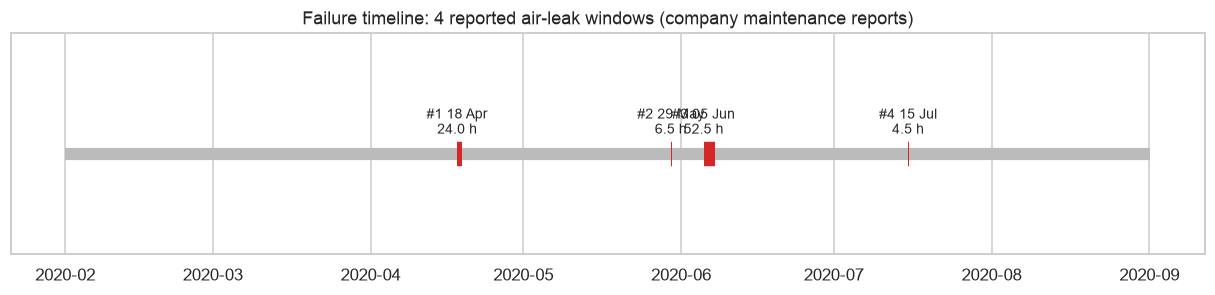

02_data_coverage.png


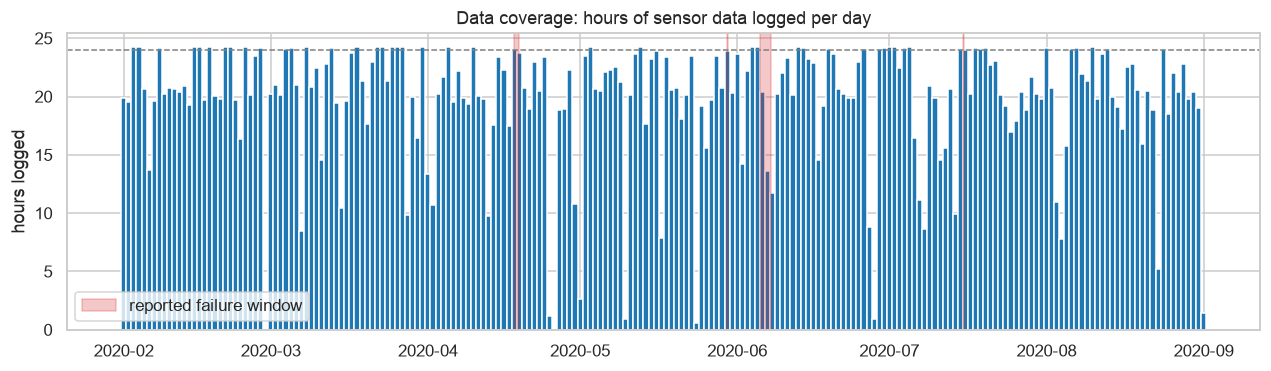

03_class_distribution.png


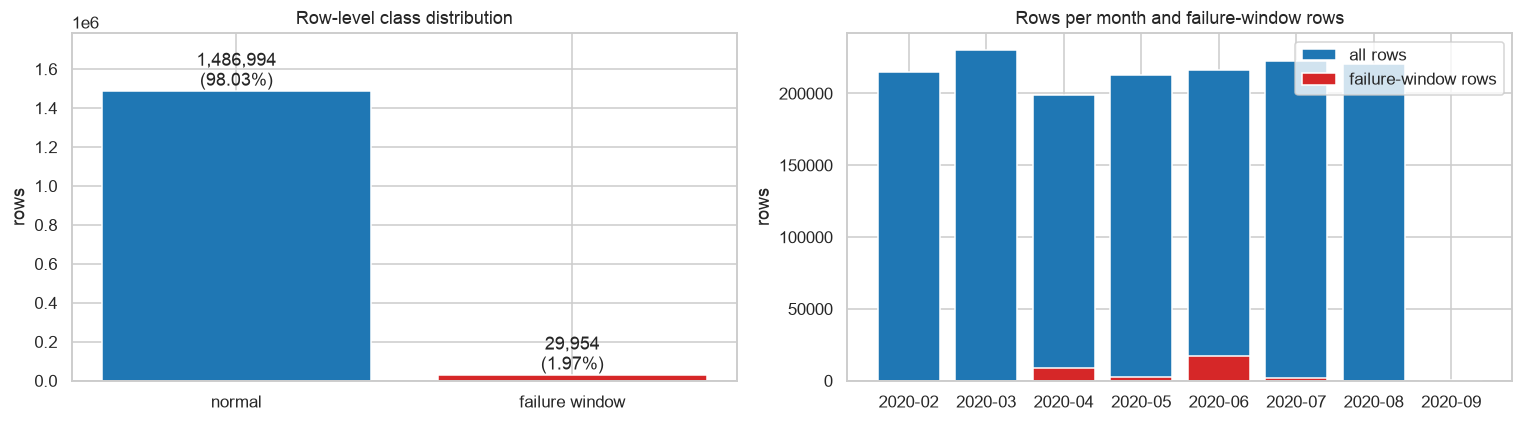

04_histograms.png


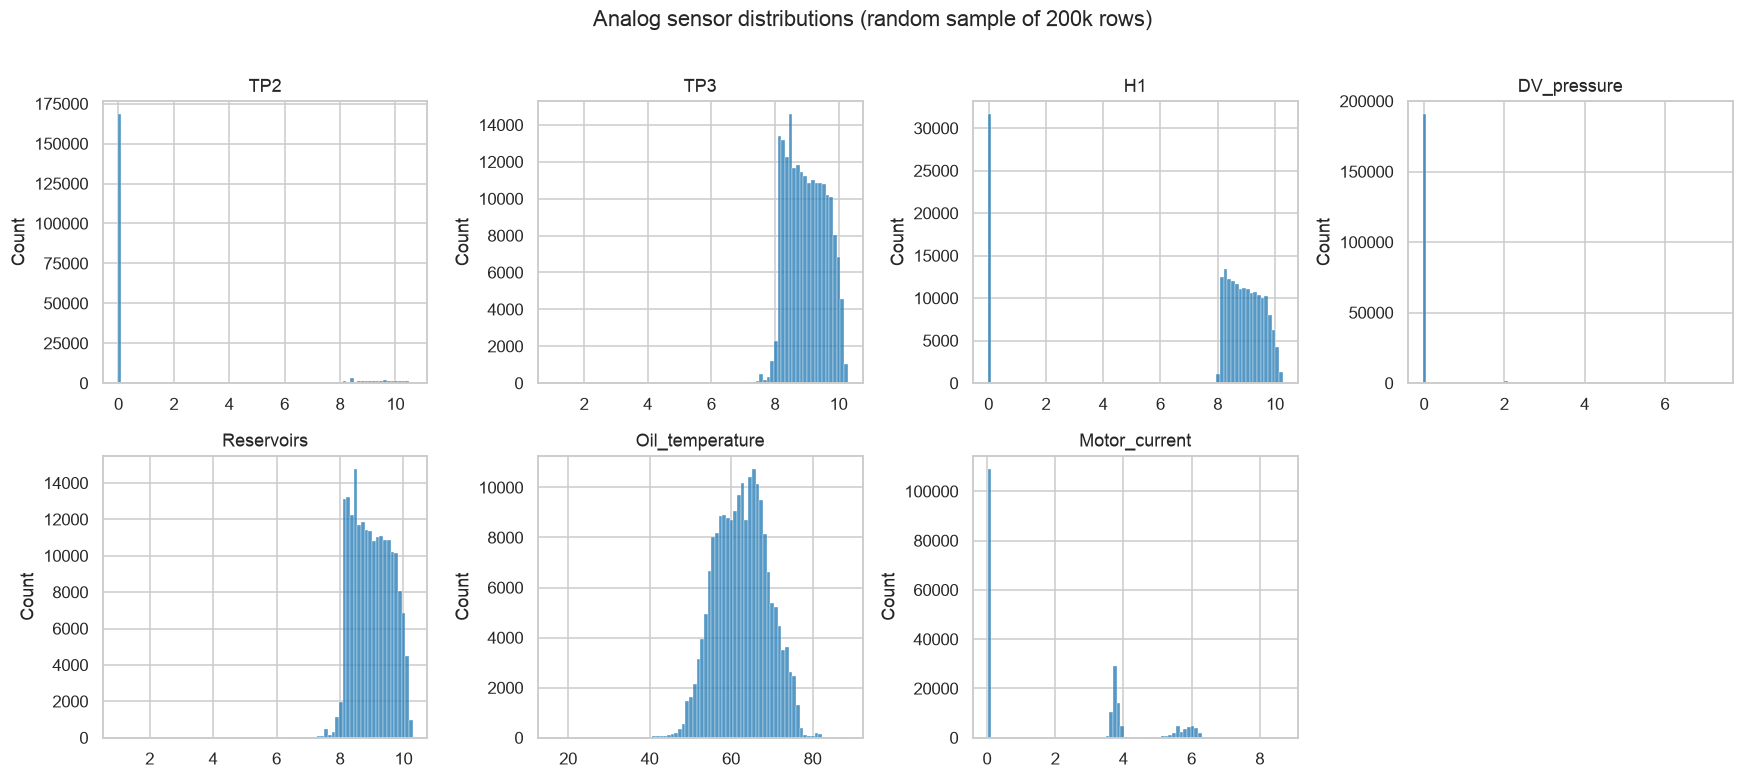

05_motor_current_regimes.png


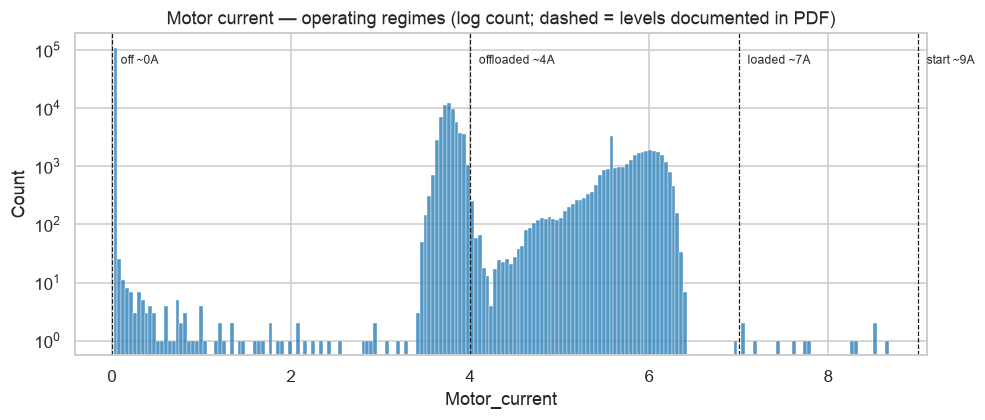

06_digital_shares.png


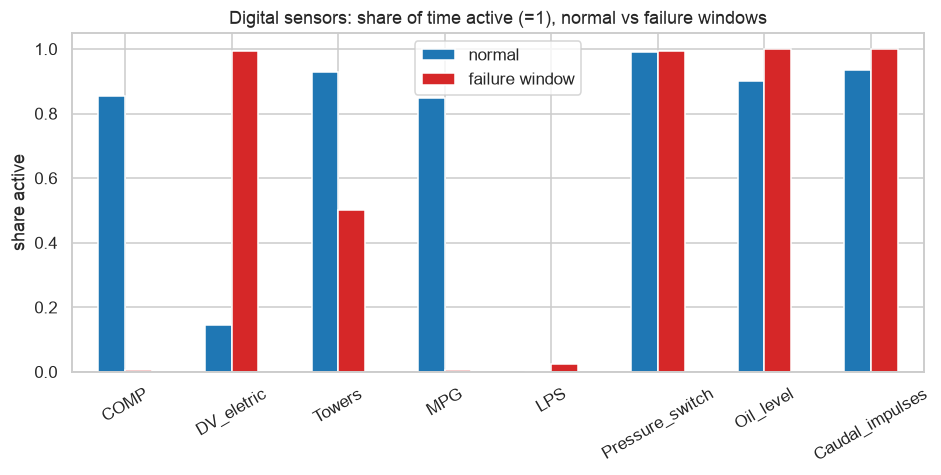

07_correlation.png


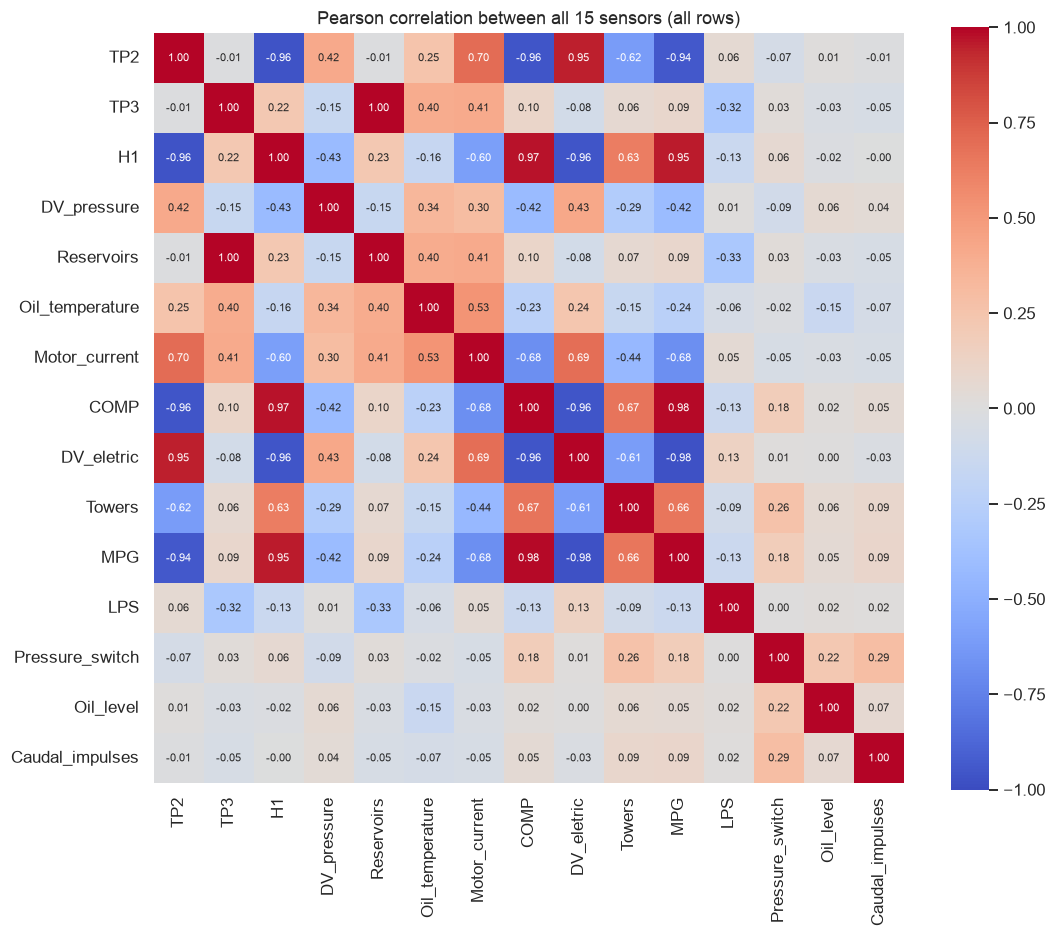

08_boxplots_by_class.png


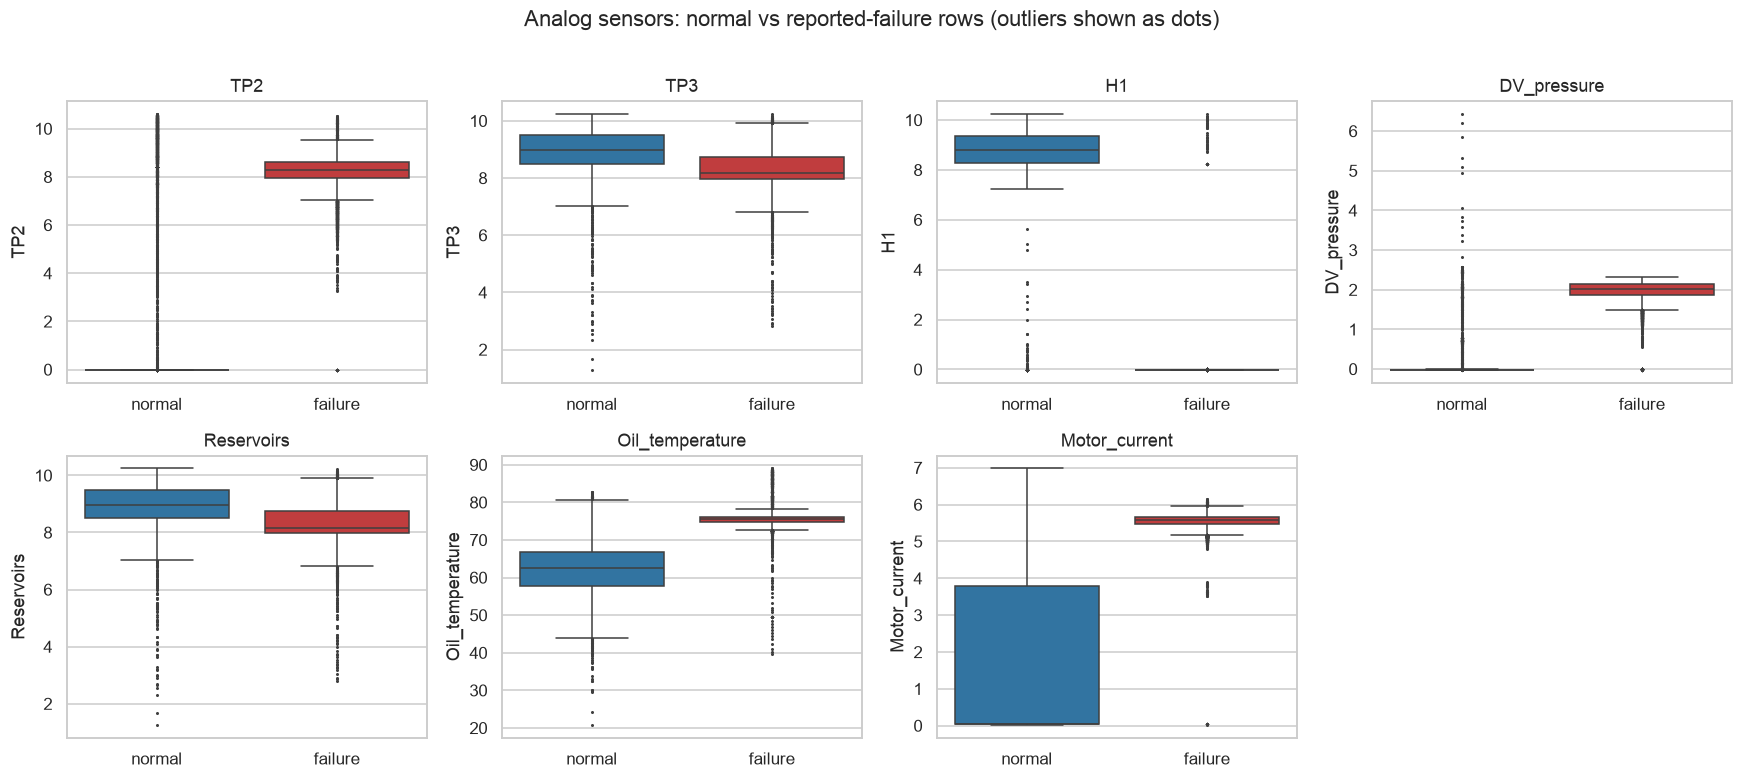

09_loaded_state_kde.png


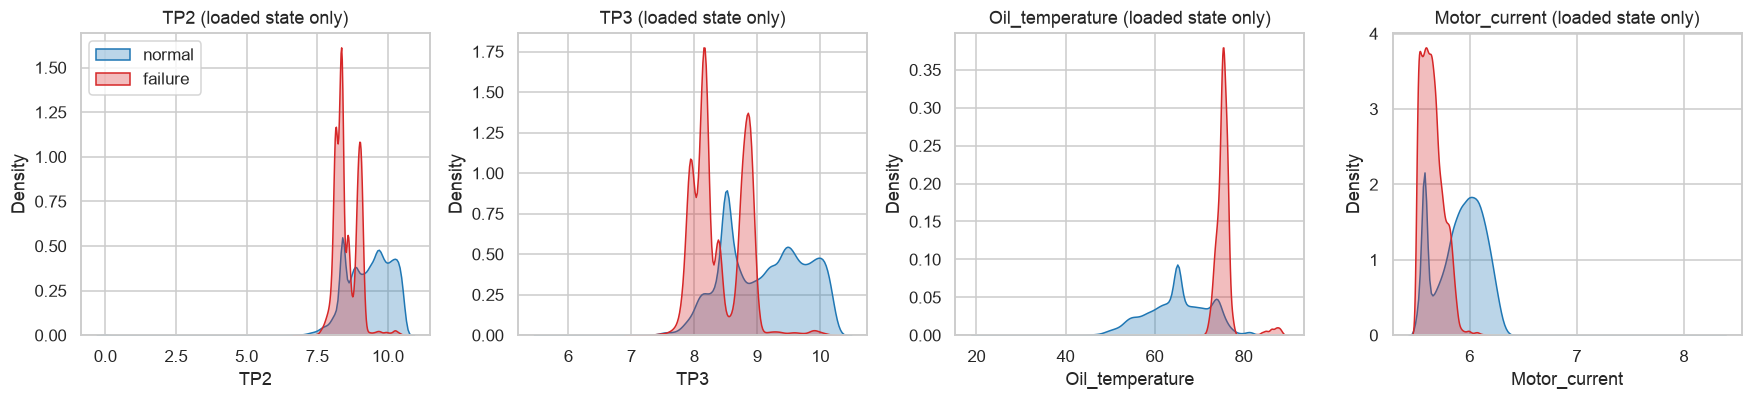

10_pairplot.png


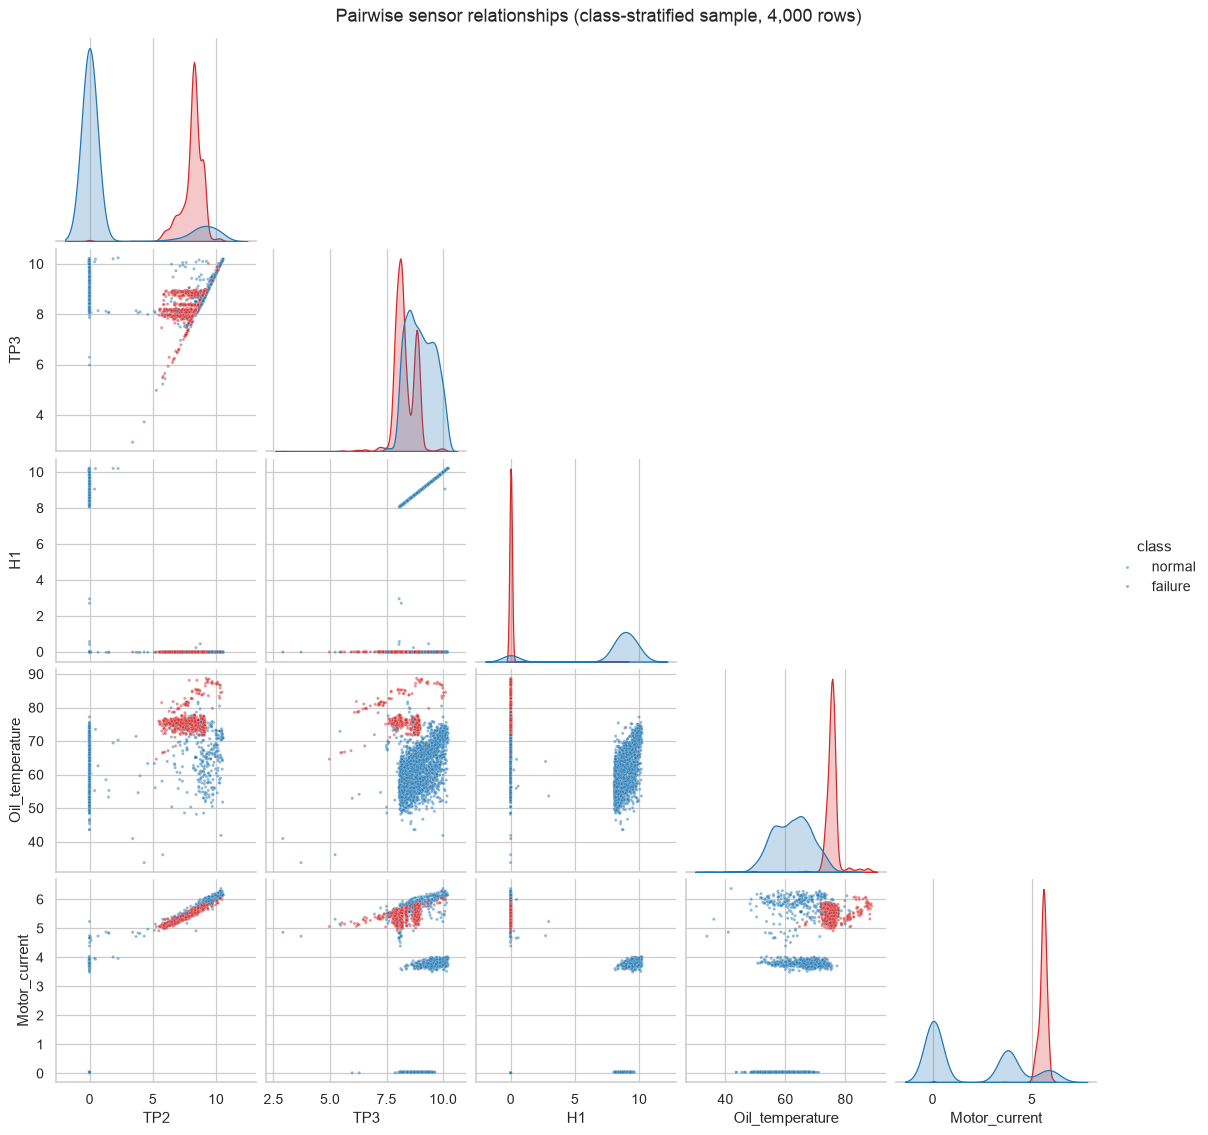

11_daily_behaviour.png


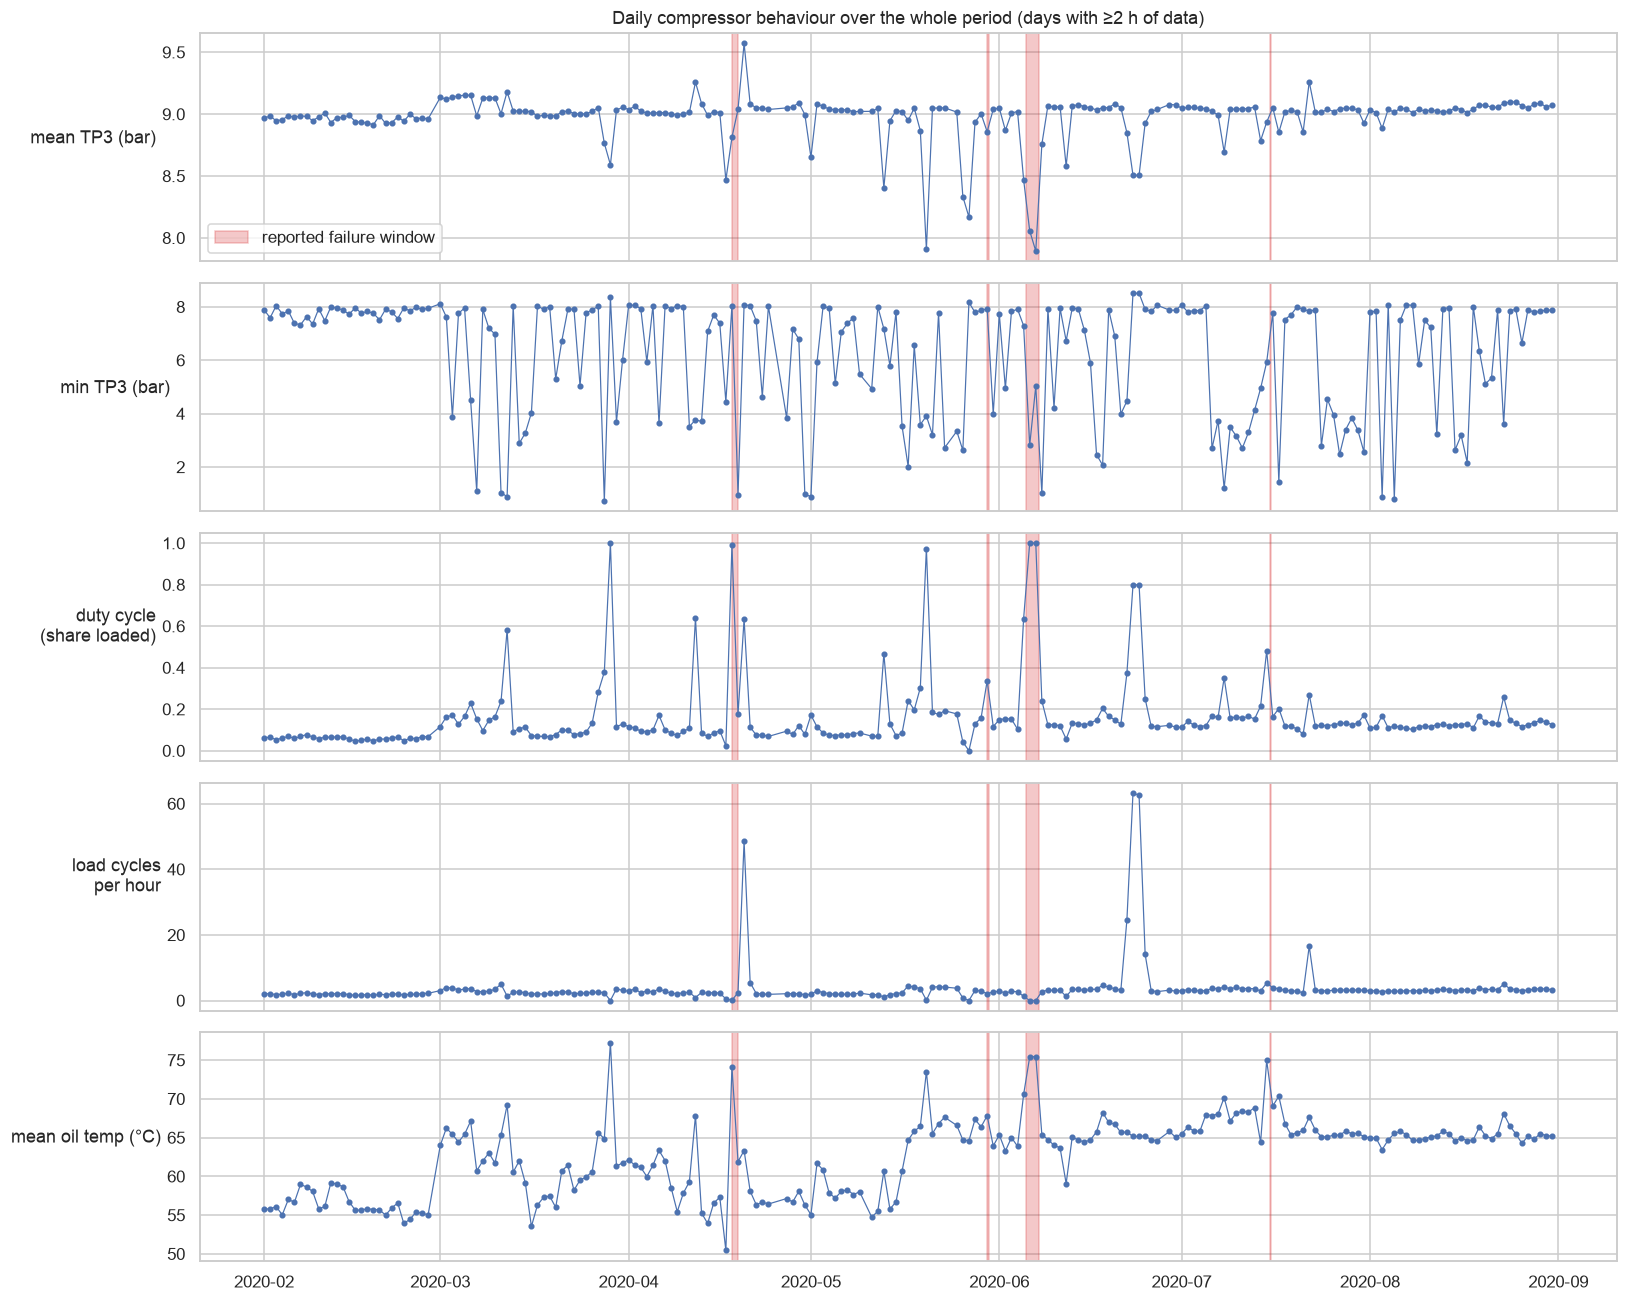

12_event1_zoom.png


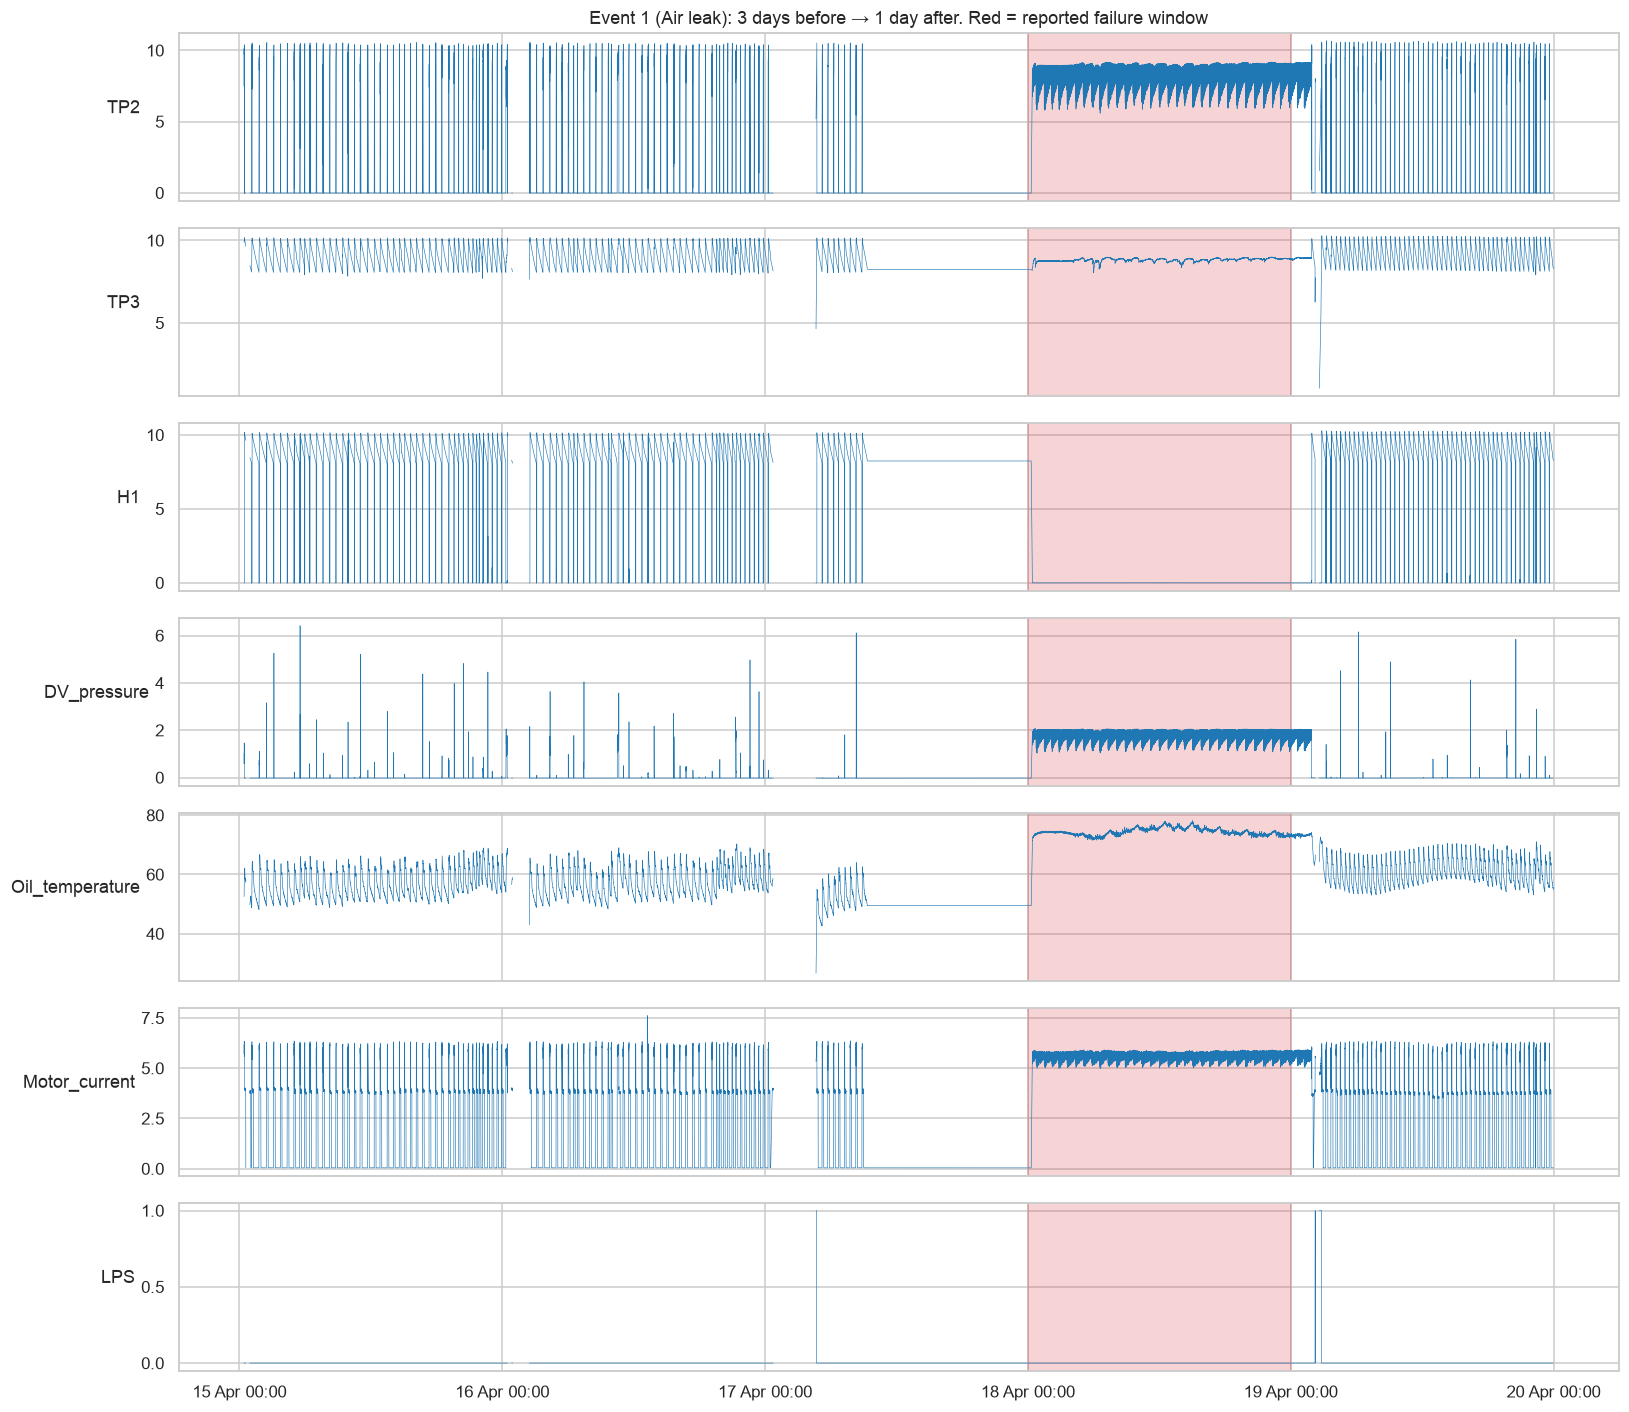

12_event2_zoom.png


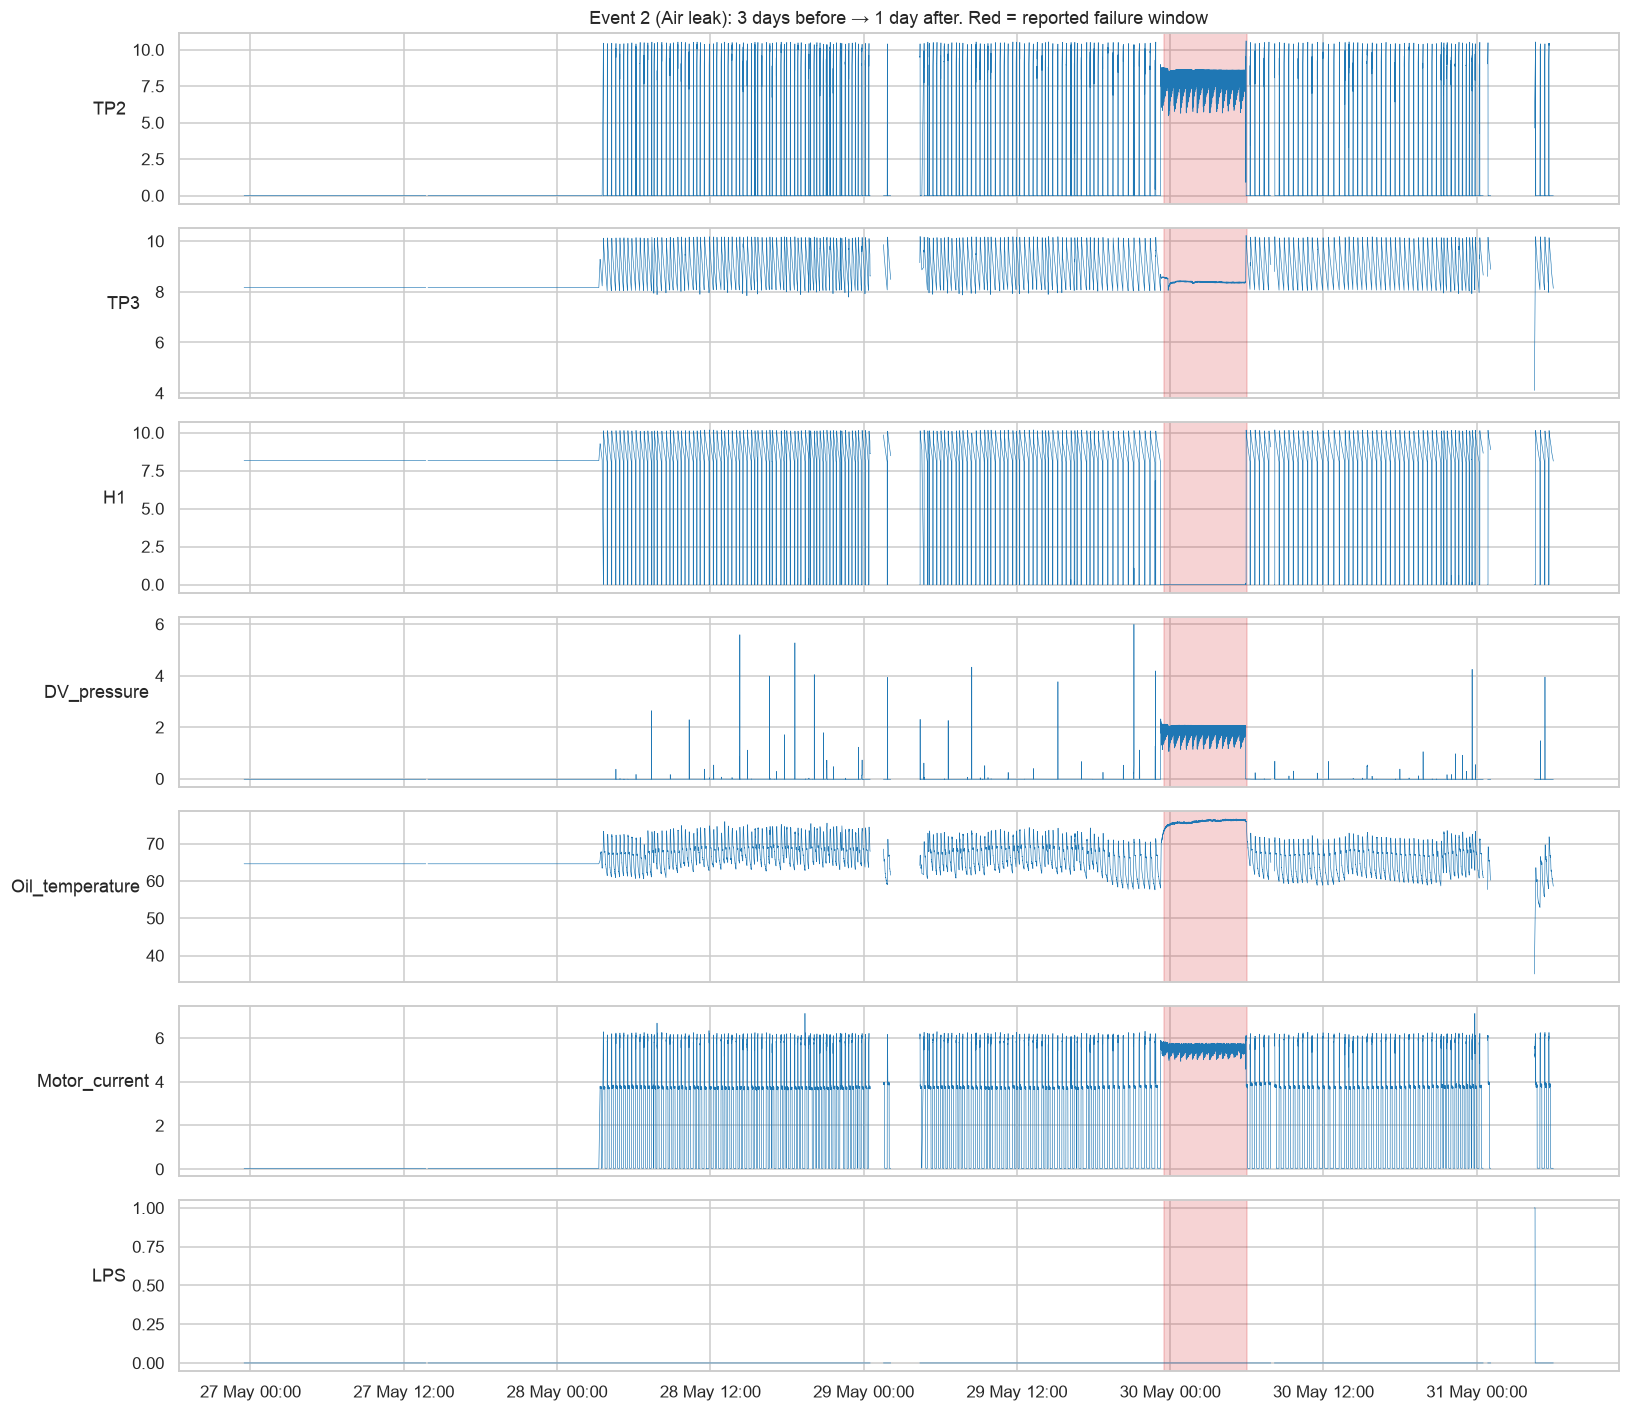

12_event3_zoom.png


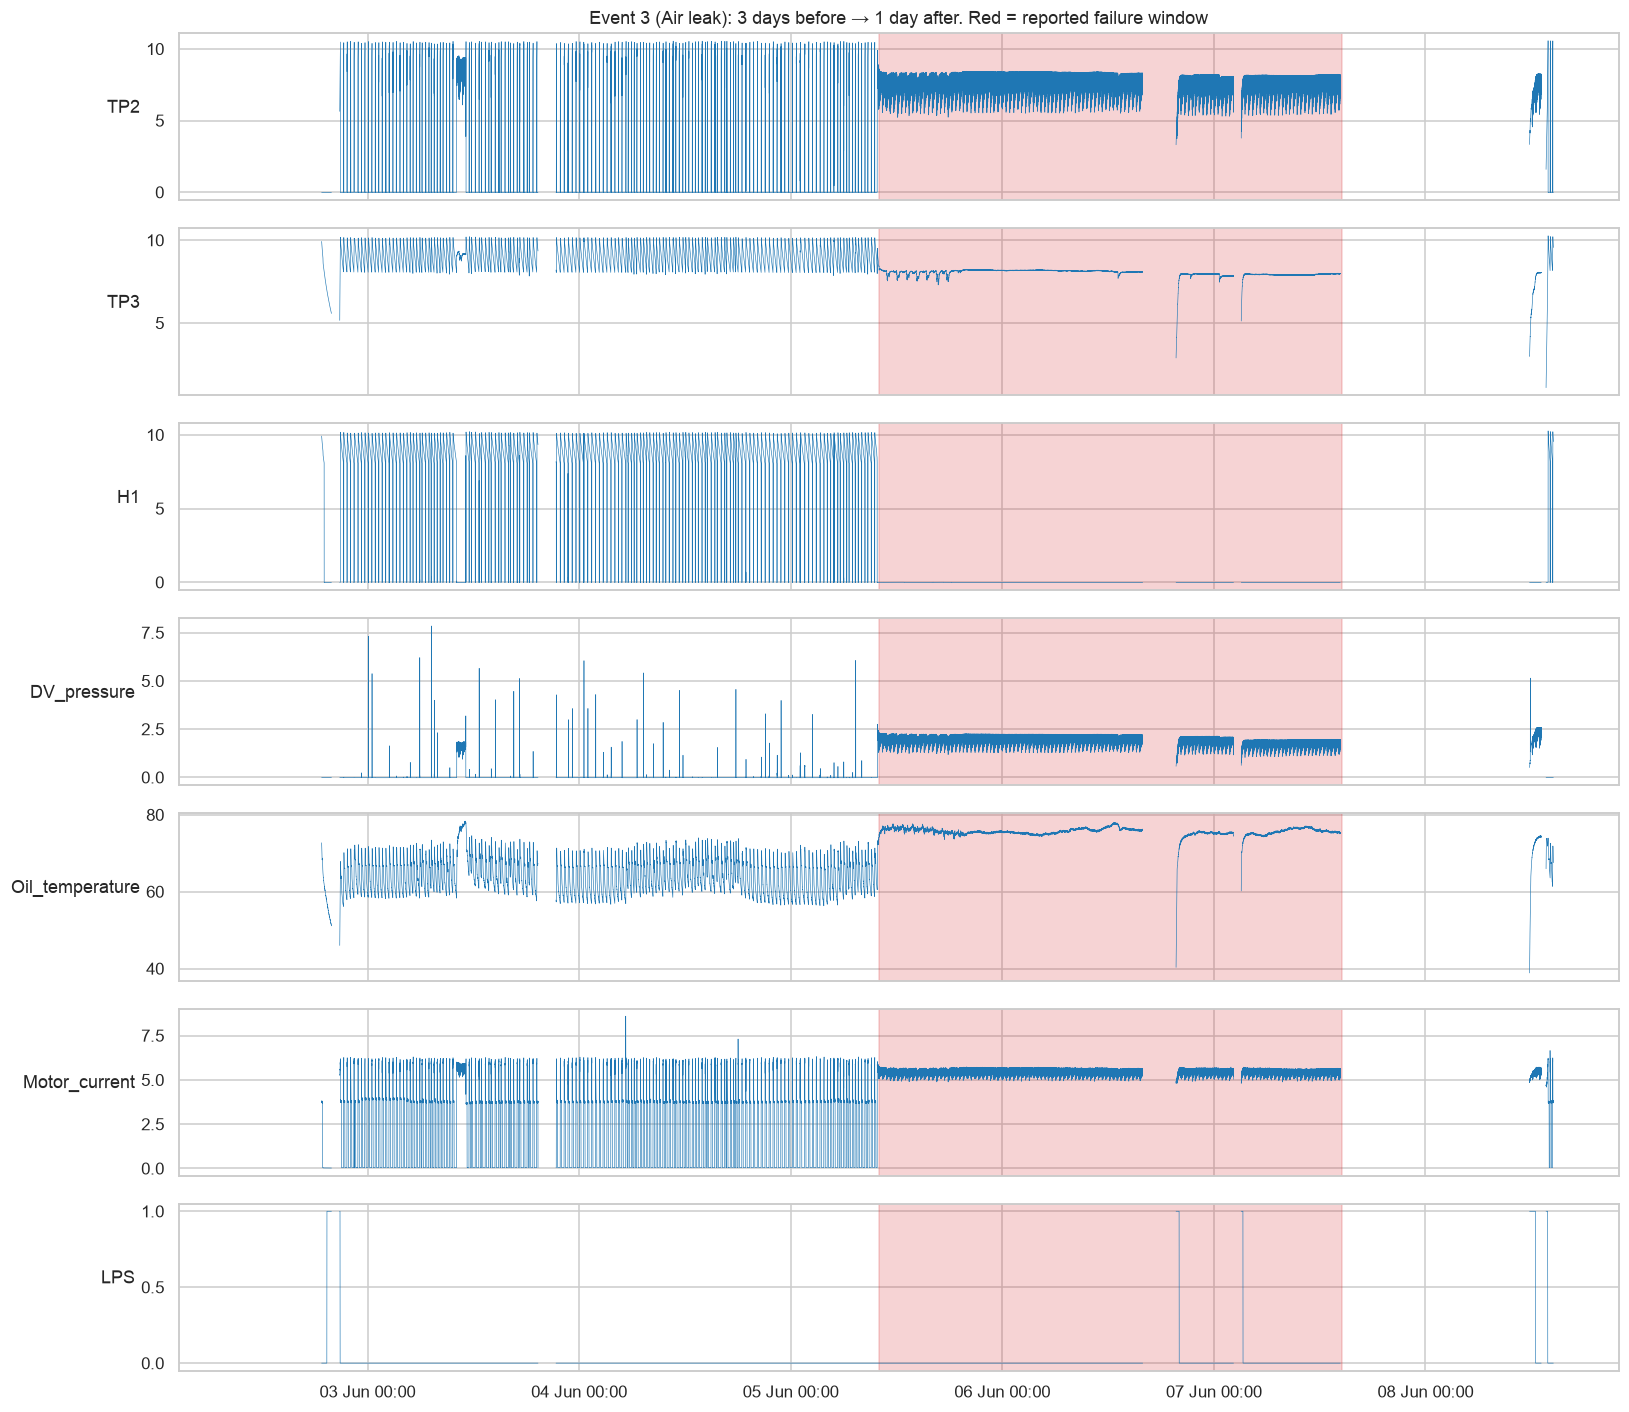

12_event4_zoom.png


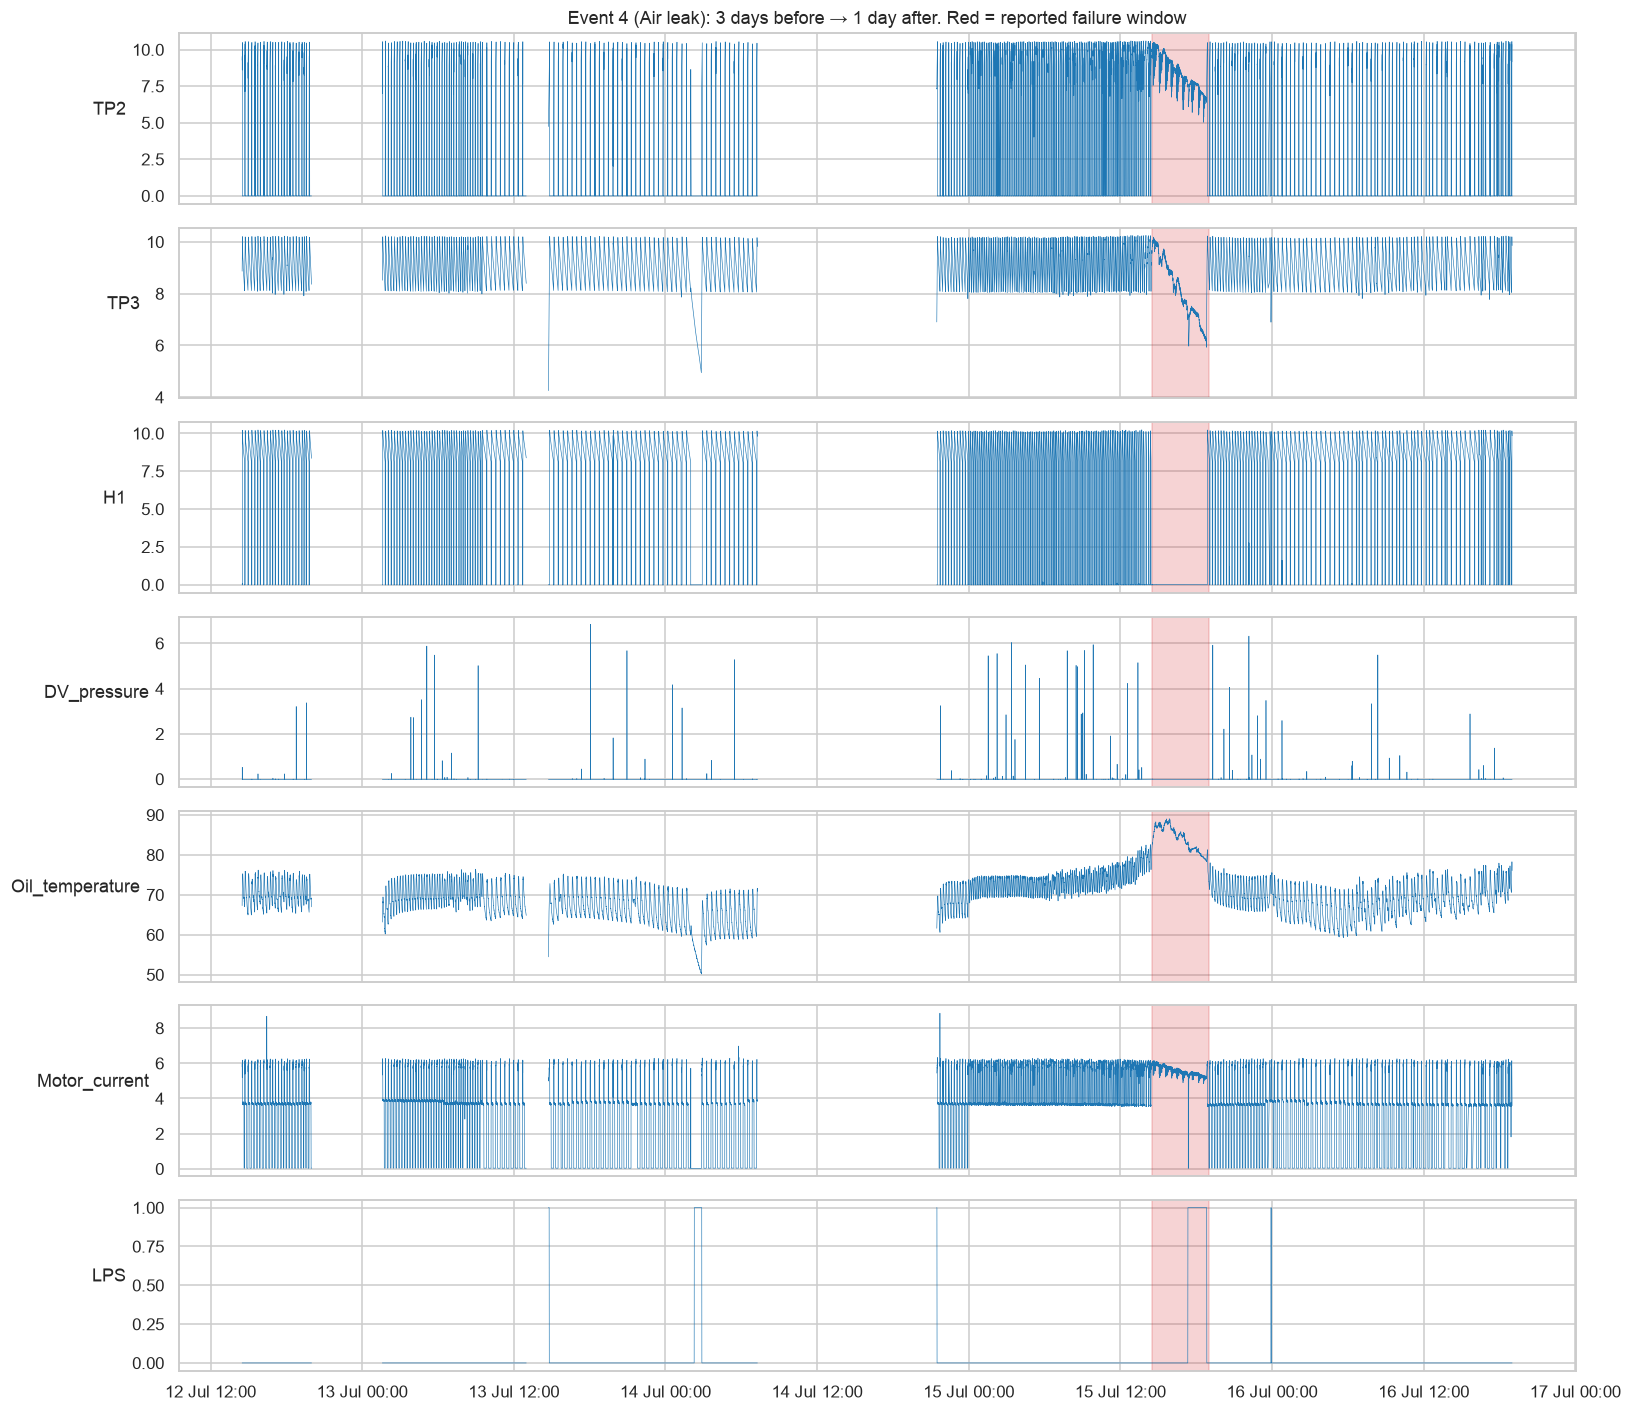

13_rolling_tp3_event3.png


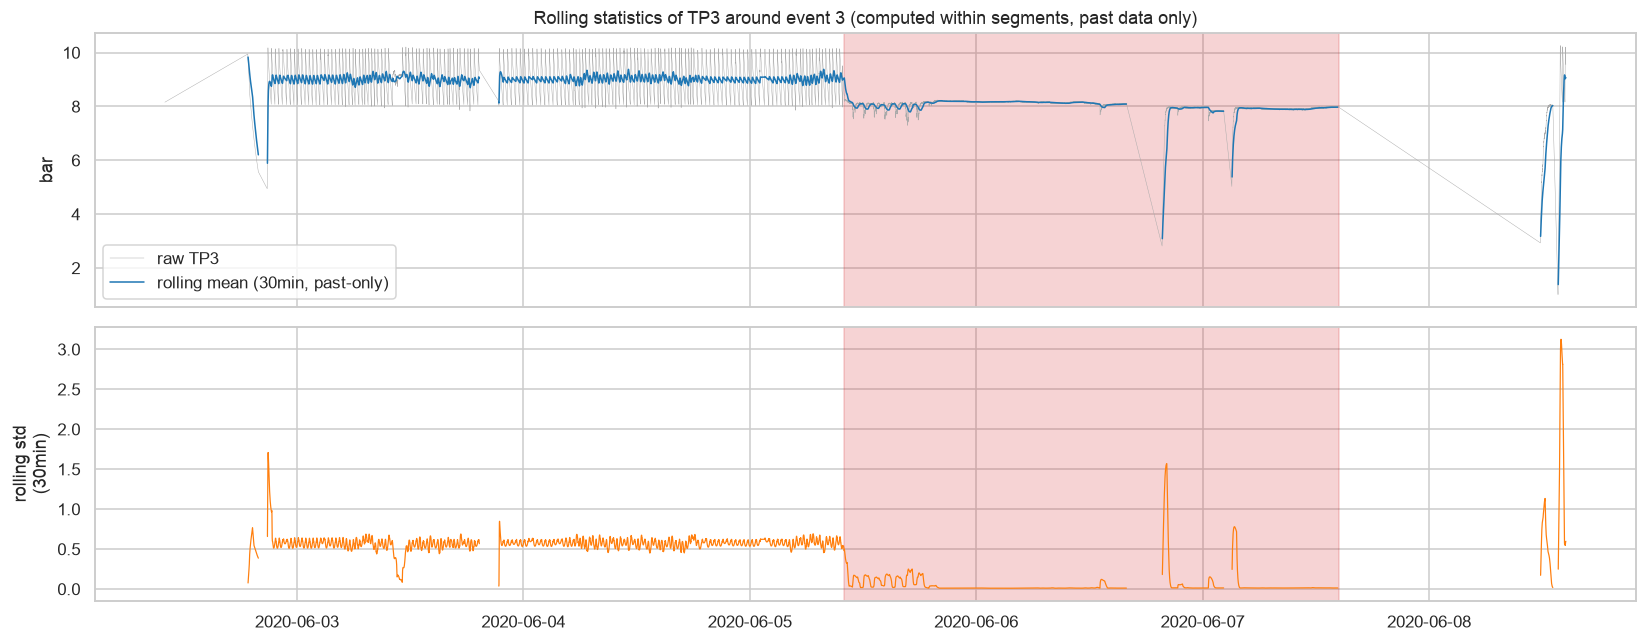

In [5]:
for p in sorted(project_path('reports/figures/eda').glob('*.png')):
    print(p.name); display(Image(filename=str(p), width=1000))